# Демонстрации к лекции 8: ограничения-равенства

Ноутбук — для самостоятельной проверки после пары. Всё, что на лекции было формулой или картинкой, здесь считается кодом. У каждой ячейки с кодом две подписи: **«Что делает ячейка»** перед ней и **«Что видим»** после неё. Числа конспекта печатаются рядом с ожидаемыми.

- **(0)** числа введения: два решения на окружности, натяжения стержней цепи и равновесие груза 1;
- **(a)** условие первого порядка (§2): система задачи 1, касательная часть $\nabla f$, окружность в пространстве с двумя множителями;
- **(b)** когда множителей нет (§3): клюв и ограничение, записанное дважды;
- **(c)** цепь на стержнях в IPOPT (§5): три проверки и силы в стержнях;
- **(e)** подробности: цена доходности, цена длины цепи, лог IPOPT из двух стартов, знак множителей у солверов.

Конспект: [`lecture08.md`](lecture08.md). Запуск: `uv run --group casadi jupyter lab` в корне репозитория. В Colab первая ячейка ставит CasADi сама.

In [1]:
%matplotlib inline

import importlib.util, subprocess, sys
if importlib.util.find_spec("casadi") is None:          # Colab: поставить CasADi один раз
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "casadi"], check=True)

import casadi as ca
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import null_space

BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#4a3aa7"
GRAY, INK = "#8a8985", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2, "legend.frameon": False})


# ---------------------------------------------------------------- задачи (те же, что в demo08 / l8helpers.py)
A_CIRCLE = np.array([2.0, 1.0])            # введение и §2.1: ближайшая к a точка единичной окружности


def circle_points(a=A_CIRCLE):
    """Оба решения системы: (x, lam) ближней и дальней точки."""
    na = np.linalg.norm(a)
    return (a / na, 1 - na), (-a / na, 1 + na)


A_SPACE = np.array([2.0, 1.0, 1.0])       # §2.2: та же окружность в пространстве, точка a поднята над плоскостью


def sphere_plane(a=A_SPACE):
    """Окружность как пересечение сферы g1 = 1/2(|x|^2 - 1) = 0 и плоскости g2 = x3 = 0; ближайшая к a точка.
    Возвращает (x*, grad f, J, lam, базис касательного пространства)."""
    xs = np.array([a[0], a[1], 0.0]) / np.hypot(a[0], a[1])   # ближайшая точка: (a1, a2) / |(a1, a2)| в плоскости x3 = 0
    gf = xs - a                                                # grad f для f = 1/2 |x - a|^2
    J = np.vstack([xs, [0.0, 0.0, 1.0]])                       # строки: grad g1 = x, grad g2 = e3
    lam = np.linalg.lstsq(J.T, gf, rcond=None)[0]              # grad f = J^T lam
    return xs, gf, J, lam, null_space(J)


def cusp_grad(x1):
    """Клюв g = x2^3 - x1^2 = 0, f = x2: в точке кривой x2 = x1^(2/3) возвращает grad g, оценку lambda, угол к grad f (град)."""
    x2 = x1 ** (2 / 3)
    gf, gg = np.array([0.0, 1.0]), np.array([-2 * x1, 3 * x2 ** 2])
    lam = gf @ gg / (gg @ gg)                                  # наименьшие квадраты для grad f = lam grad g
    ang = np.degrees(np.arccos(gf @ gg / np.linalg.norm(gg)))
    return gg, lam, ang


def rod_chain(N=3, L_total=5.0, m=1.0, g_acc=9.81):
    """Цепь на стержнях: N грузов массы m между (-2, 1) и (2, 1), N + 1 стержней длины L_total / (N + 1), f = w sum z.
    Возвращает словарь с символьными v, f, g (CasADi), весом груза w, длиной стержня ell и стартом v0."""
    w = m * g_acc; ell = L_total / (N + 1)
    v = ca.SX.sym("v", 2 * N)
    y = ca.vertcat(-2.0, v[:N], 2.0); z = ca.vertcat(1.0, v[N:], 1.0)
    f = w * ca.sum1(z[1:-1])
    g = ca.vertcat(*[(y[j + 1] - y[j]) ** 2 + (z[j + 1] - z[j]) ** 2 - ell ** 2 for j in range(N + 1)])
    t = np.linspace(-2, 2, N + 2)[1:-1]
    v0 = np.concatenate([t, np.zeros(N)])                     # старт: грузы равномерно по y на прямой z = 0
    return dict(v=v, f=f, g=g, w=w, ell=ell, N=N, v0=v0)


def solve_rod_chain(ch, v0=None, tol=1e-10):
    """IPOPT для цепи на стержнях. Возвращает (v*, lam* в нашем знаке L = f - lam^T g, stats)."""
    solver = ca.nlpsol("s", "ipopt", {"x": ch["v"], "f": ch["f"], "g": ch["g"]},
                       {"ipopt.print_level": 0, "print_time": 0, "ipopt.sb": "yes", "ipopt.tol": tol})
    sol = solver(x0=ch["v0"] if v0 is None else v0, lbg=0, ubg=0)
    return np.array(sol["x"]).ravel(), -np.array(sol["lam_g"]).ravel(), solver.stats()   # IPOPT: L = f + lam_g^T g


def chain_xy(ch, v):
    """Координаты y и z всех точек цепи вместе с опорами (-2, 1) и (2, 1) по краям."""
    N = ch["N"]
    y = np.concatenate([[-2.0], v[:N], [2.0]])                # v[:N] — y-координаты грузов
    z = np.concatenate([[1.0], v[N:], [1.0]])                 # v[N:] — z-координаты грузов
    return y, z


def chain_checks(ch, v, lam):
    """Три проверки §5.1: невязка стационарности, ранг J, собственные числа редуцированного гессиана; натяжения."""
    J = ca.Function("J", [ch["v"]], [ca.jacobian(ch["g"], ch["v"])])(v).full()
    gf = ca.Function("gf", [ch["v"]], [ca.gradient(ch["f"], ch["v"])])(v).full().ravel()
    lsym = ca.SX.sym("l", ch["N"] + 1)
    H = ca.Function("H", [ch["v"], lsym], [ca.hessian(ch["f"] - ca.dot(lsym, ch["g"]), ch["v"])[0]])(v, lam).full()
    Z = null_space(J)
    y, z = chain_xy(ch, v)
    F = 2 * np.abs(lam) * ch["ell"]                            # натяжение стержня
    Fh = 2 * lam * np.diff(y)                                  # горизонтальная составляющая
    return dict(res=np.linalg.norm(gf - J.T @ lam), rank=np.linalg.matrix_rank(J), eig=np.linalg.eigvalsh(Z.T @ H @ Z),
                Z=Z, F=F, Fh=Fh, Fv=2 * lam * np.diff(z))


PF_R = np.array([0.04, 0.08, 0.11, 0.15])                              # портфель Л3: доходности
PF_VOL = np.array([0.05, 0.12, 0.18, 0.30])
PF_CORR = np.array([[1, 0.2, 0.1, 0.0], [0.2, 1, 0.5, 0.3], [0.1, 0.5, 1, 0.4], [0.0, 0.3, 0.4, 1.0]])
PF_SIGMA = np.outer(PF_VOL, PF_VOL) * PF_CORR


def portfolio_eq(rho):
    """min 1/2 x'Sx при 1'x = 1, r'x = rho — только равенства: система ККТ линейна. Возвращает (x, f*, lam)."""
    Aeq = np.c_[np.ones(4), PF_R].T
    K = np.block([[PF_SIGMA, -Aeq.T], [Aeq, np.zeros((2, 2))]])
    rhs = np.concatenate([np.zeros(4), [1.0, rho]])           # правая часть: 0 — стационарность, 1 и rho — ограничения
    sol = np.linalg.solve(K, rhs)
    return sol[:4], 0.5 * sol[:4] @ PF_SIGMA @ sol[:4], sol[4:]


def level_circles(ax, a, levels, color=BLUE, lw=1.2, alpha=0.8):
    """Линии уровня f = 1/2 |x - a|^2 — окружности вокруг a радиуса sqrt(2 f)."""
    th = np.linspace(0, 2 * np.pi, 400)
    for f in levels:
        r = np.sqrt(2 * f)
        ax.plot(a[0] + r * np.cos(th), a[1] + r * np.sin(th), color=color, lw=lw, alpha=alpha)


def unit_circle(ax, color=INK, lw=2.2):
    """Единичная окружность — ограничение задачи 1."""
    th = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), color=color, lw=lw)

## (0) Числа введения

**Что проверяем.** Задача 1: у системы касания два решения, и система их не различает. Задача 2: IPOPT решает цепь за 5 итераций, множители — натяжения стержней, а три силы на груз 1 в сумме дают ноль.

**Задача 1. Что делает ячейка.** Система задачи 1 — три уравнения:

$$
x_1-2=\lambda x_1,\qquad x_2-1=\lambda x_2,\qquad x_1^2+x_2^2=1 .
$$

Её решения найдены в §2 явно: $x=\pm a/\sqrt5$, $\lambda=1\mp\sqrt5$. Ячейка подставляет обе точки в три уравнения и печатает невязки (левая часть минус правая), $\lambda$ и $f$.

In [2]:
a = A_CIRCLE                                                           # a = (2, 1)
for s in (+1, -1):                                                     # два решения: x = +a/sqrt5 и x = -a/sqrt5
    x1, x2 = s * a / np.sqrt(5)                                        # координаты точки
    lam = 1 - s * np.sqrt(5)                                           # её множитель: 1 - sqrt5 или 1 + sqrt5
    residuals = [x1 - 2 - lam * x1, x2 - 1 - lam * x2, x1**2 + x2**2 - 1]   # три уравнения: левая часть минус правая
    f = 0.5 * ((x1 - 2)**2 + (x2 - 1)**2)                              # значение f в этой точке
    print(f"x = ({x1:+.3f}, {x2:+.3f}), lambda = {lam:+.3f}, f = {f:.3f}, невязки = {np.abs(residuals).max():.0e}")
print("в конспекте: lambda = -1.236 (f = 0.764) и +3.236 (f = 5.236)")

x = (+0.894, +0.447), lambda = -1.236, f = 0.764, невязки = 1e-16
x = (-0.894, -0.447), lambda = +3.236, f = 5.236, невязки = 1e-16
в конспекте: lambda = -1.236 (f = 0.764) и +3.236 (f = 5.236)


**Что видим.** В обеих точках невязки — машинный ноль: обе удовлетворяют системе. Значения $f$ разные: $0.764$ — минимум, $5.236$ — максимум. Сама система этого не различает; различит условие второго порядка (§4).

**Задача 2. Что делает ячейка.**

- `rod_chain()` строит задачу цепи в CasADi: 6 переменных $v=(y_1,y_2,y_3,z_1,z_2,z_3)$, функцию $f=w\,(z_1+z_2+z_3)$ и 4 ограничения $g_j$.
- `solve_rod_chain` вызывает IPOPT. Он возвращает координаты грузов, множители и статистику.
- `chain_checks` переводит множители в натяжения $2\lvert\lambda_j\rvert\ell$ (§5.1).
- Затем ячейка считает три силы на груз 1 из введения: вес $(0,-w)$, $2\lambda_0(p_1-p_0)$ и $2\lambda_1(p_1-p_2)$. И складывает их.

In [3]:
ch = rod_chain()                                                       # задача: 3 груза по 1 кг, 4 стержня длины 1.25 м, f = w (z1 + z2 + z3)
v, lam, st = solve_rod_chain(ch)                                       # IPOPT; lam — в нашем знаке L = f - lam^T g
chk = chain_checks(ch, v, lam)                                         # натяжения 2 |lam_j| ell и их составляющие
y, z = chain_xy(ch, v)                                                 # координаты точек 0..4: опоры и грузы
print(f"IPOPT: {st['iter_count']} итераций (в конспекте 5), f* = {ch['w'] * z[1:-1].sum():.3f} Дж")
print(f"lambda = {lam.round(2)}   (в конспекте -7.87 и -5.58)")
print(f"натяжения 2|lambda_j| ell = {chk['F'].round(1)} Н   (в конспекте 19.7 и 14.0)")
p0, p1, p2 = (np.array([y[i], z[i]]) for i in range(3))               # опора 0, груз 1, груз 2
weight = np.array([0.0, -ch["w"]])                                     # вес груза 1
rod0 = 2 * lam[0] * (p1 - p0)                                          # сила стержня 0 на груз 1
rod1 = 2 * lam[1] * (p1 - p2)                                          # сила стержня 1 на груз 1
print(f"силы на груз 1: вес {weight.round(2)}, стержень 0 {rod0.round(2)}, стержень 1 {rod1.round(2)}")
print(f"их сумма: {(weight + rod0 + rod1).round(10)}")

IPOPT: 5 итераций (в конспекте 5), f* = -2.394 Дж
lambda = [-7.87 -5.58 -5.58 -7.87]   (в конспекте -7.87 и -5.58)
натяжения 2|lambda_j| ell = [19.7 14.  14.  19.7] Н   (в конспекте 19.7 и 14.0)
силы на груз 1: вес [ 0.   -9.81], стержень 0 [-13.06  14.72], стержень 1 [13.06 -4.9 ]
их сумма: [0. 0.]


**Что видим.** IPOPT сделал 5 итераций. Множители отрицательны, натяжения — 19.7 Н у опор и 14.0 Н в середине. Три силы на груз 1 в сумме дают ноль: это равновесие из введения. По горизонтали стержни тянут в разные стороны с силой 13.06 Н. По вертикали стержень 0 тянет вверх с силой 14.72 Н, а вес и стержень 1 — вниз: $9.81+4.91$.

## (a) Условие первого порядка (раздел 2)

**Что проверяем.** Система задачи 1 находит обе точки касания. В них у $\nabla f$ нет касательной части, а в других точках окружности — есть. С двумя ограничениями множителей два.

**Шаг 1. Что делает ячейка.** Функция `circle_system` получает вектор неизвестных $z=(x_1,x_2,\lambda)$. Она возвращает левые части трёх уравнений задачи 1, перенесённые в одну сторону:

$$
x_1-2-\lambda x_1,\qquad x_2-1-\lambda x_2,\qquad x_1^2+x_2^2-1 .
$$

Решение системы — такое $z$, где все три числа равны нулю. Его ищет `fsolve` из SciPy: итерации типа метода Ньютона от стартовой точки. Из старта справа он находит ближнюю точку, из старта слева — дальнюю.

In [4]:
from scipy.optimize import fsolve

a = A_CIRCLE                                           # a = (2, 1) — точка, к которой ищем ближайшую

def circle_system(z):
    """Левые части трёх уравнений задачи 1 при a = (2, 1). Решение системы — z, где все три равны нулю."""
    x1, x2, lam = z                                    # неизвестные: координаты точки и множитель
    return [x1 - 2 - lam * x1,                         # первая компонента grad f = lambda grad g
            x2 - 1 - lam * x2,                         # вторая компонента
            x1**2 + x2**2 - 1]                         # точка лежит на окружности

sols = []
for start in ([1.0, 0.5, 0.0], [-1.0, -0.5, 0.0]):    # стартовые (x1, x2, lambda): справа и слева
    z = fsolve(circle_system, start, xtol=1e-14)       # решение системы из этого старта
    sols.append(z)
    print(f"старт {start}: x = ({z[0]:+.4f}, {z[1]:+.4f}), lambda = {z[2]:+.4f}, невязки = {np.abs(circle_system(z)).max():.0e}")

старт [1.0, 0.5, 0.0]: x = (+0.8944, +0.4472), lambda = -1.2361, невязки = 1e-16
старт [-1.0, -0.5, 0.0]: x = (-0.8944, -0.4472), lambda = +3.2361, невязки = 1e-16


**Что видим.** Два старта — два решения, те же, что в части (0): $\lambda=-1.236$ и $\lambda=3.236$. Невязки — машинный ноль.

**Шаг 2. Что делает ячейка.** Касательная часть $\nabla f$ — это проекция $\nabla f$ на касательную к окружности. Ограничение одно, поэтому якобиан — одна строка $J=\nabla g^\top=x^\top$. Функция `null_space(J)` возвращает единичный вектор $Z$ с $JZ=0$, то есть направление касательной. Касательная часть — число $Z^\top\nabla f$. Считаем его в двух решениях и в точке $(0.5,\ 0.866)$.

In [5]:
grad_f = lambda x: x - a                               # grad f для f = 1/2 |x - a|^2
grad_g = lambda x: x                                   # grad g для g = 1/2 (|x|^2 - 1)

def tangent_part(x):
    """Касательная часть grad f в точке x окружности: Z^T grad f, где Z — единичная касательная."""
    J = grad_g(x).reshape(1, -1)                       # якобиан: одна строка grad g^T
    Z = null_space(J)                                  # 2 x 1 — касательное направление, J Z = 0
    return (Z.T @ grad_f(x)).item()                    # проекция grad f на касательную

for name, x in (("ближняя точка", sols[0][:2]), ("дальняя точка", sols[1][:2]), ("точка (0.5, 0.866)", np.array([0.5, np.sqrt(3) / 2]))):
    print(f"{name:18s}: касательная часть grad f = {tangent_part(x):+.4f}")

ближняя точка     : касательная часть grad f = +0.0000
дальняя точка     : касательная часть grad f = -0.0000
точка (0.5, 0.866): касательная часть grad f = +1.2321


**Что видим.** В обоих решениях касательная часть — ноль: условие первого порядка выполнено. В точке $(0.5,\ 0.866)$ она равна $1.232$ по модулю. Значит, там $f$ меняется при движении по окружности: сдвиг против касательной части уменьшает $f$. Это картинка 02 конспекта.

**Шаг 3. Что делает ячейка.** Два ограничения: окружность в пространстве как пересечение сферы $\tfrac12(\lVert x\rVert^2-1)=0$ и плоскости $x_3=0$, точка $a=(2,1,1)$. Функция `sphere_plane()` находит ближайшую точку и строит якобиан $J$ — матрицу $2\times3$, по строке на ограничение. Множители она находит из $\nabla f=J^\top\lambda$ методом наименьших квадратов: три уравнения на два неизвестных. Если невязка — ноль, разложение $\nabla f$ по двум нормалям точное.

In [6]:
xs, gf, J, lam, T = sphere_plane()                                   # окружность = сфера ∩ плоскость, a = (2, 1, 1)
print(f"x* = {xs.round(3)},  grad f = {gf.round(3)}")
print(f"J =\n{J.round(3)}\nrank J = {np.linalg.matrix_rank(J)}")
print(f"lambda = {lam.round(3)}   (в конспекте -1.236 и -1);  |grad f - J^T lambda| = {np.linalg.norm(gf - J.T @ lam):.1e}")
print(f"базис T = {T.ravel().round(3)},  |J T| = {np.abs(J @ T).max():.1e}")

x* = [0.894 0.447 0.   ],  grad f = [-1.106 -0.553 -1.   ]
J =
[[0.894 0.447 0.   ]
 [0.    0.    1.   ]]
rank J = 2
lambda = [-1.236 -1.   ]   (в конспекте -1.236 и -1);  |grad f - J^T lambda| = 2.5e-16
базис T = [ 0.447 -0.894  0.   ],  |J T| = 1.3e-17


**Что видим.** $\lambda=(-1.236,\ -1)$, невязка — машинный ноль: $\nabla f$ точно раскладывается по двум нормалям. Ранг $J$ равен 2, ограничения независимы. Касательное пространство — один вектор, касательная к окружности в плоскости $x_3=0$.

**Шаг 4. Что делает ячейка.** Рисует обе точки. Линии уровня $f$ — окружности вокруг $a$. Две из них касаются единичной окружности в найденных точках. Красная стрелка — $\nabla f$, зелёная — $\nabla g$.

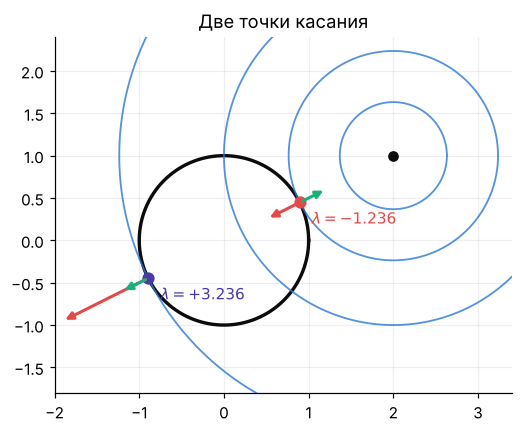

In [7]:
fig, ax = plt.subplots(figsize=(6, 4.2))
unit_circle(ax)                                                         # ограничение g = 0
level_circles(ax, a, [0.5 * np.sum((z[:2] - a) ** 2) for z in sols] + [0.2, 2.0], color=BLUE)   # линии уровня f, две — касаются
for z, col in zip(sols, (RED, VIOLET)):
    x = z[:2]
    ax.annotate("", x + 0.35 * grad_f(x), x, arrowprops=dict(arrowstyle="-|>", color=RED, lw=2))       # grad f
    ax.annotate("", x + 0.35 * grad_g(x), x, arrowprops=dict(arrowstyle="-|>", color=AQUA, lw=2))      # grad g
    ax.plot(*x, "o", color=col, ms=7); ax.annotate(f"$\\lambda={z[2]:+.3f}$", x, (8, -14), textcoords="offset points", color=col)
ax.plot(*a, "o", color=INK); ax.set_aspect("equal"); ax.set_xlim(-2, 3.4); ax.set_ylim(-1.8, 2.4)
ax.set_title("Две точки касания"); plt.show()

**Что видим.** В обеих точках стрелки лежат на одной прямой — на нормали к окружности. В ближней точке они направлены в разные стороны ($\lambda<0$), в дальней — в одну ($\lambda>0$).

## (b) Когда множителей нет (раздел 3)

**Что проверяем.** На клюве $x_2^3=x_1^2$ при $f=x_2$ множителя в минимуме нет: лучший множитель уходит в бесконечность. Если ограничение записано дважды, множители есть, но их бесконечно много.

**Шаг 1. Что делает ячейка.** Берёт точки кривой $x_2=x_1^{2/3}$ всё ближе к острию: $x_1$ от $0.5$ до $10^{-4}$. В каждой считает $\nabla g$, лучший множитель $\hat\lambda$ и невязку $\lVert\nabla f-\hat\lambda\nabla g\rVert$. Лучший множитель — это $\lambda$, при котором $\lambda\nabla g$ ближе всего к $\nabla f$:

$$
\hat\lambda=\frac{\nabla f^\top\nabla g}{\lVert\nabla g\rVert^2} .
$$

Последний столбец — угол между $\nabla f$ и $\nabla g$.

In [8]:
print(f"{'x1':>8s} {'|grad g|':>10s} {'lambda^':>9s} {'невязка':>9s} {'угол':>7s}")
for x1 in (0.5, 0.1, 0.01, 0.001, 1e-4):
    gg, lam_hat, ang = cusp_grad(x1)                                    # grad g, лучший множитель, угол к grad f
    res = np.linalg.norm(np.array([0.0, 1.0]) - lam_hat * gg)          # |grad f - lambda^ grad g|, grad f = (0, 1)
    print(f"{x1:8.0e} {np.linalg.norm(gg):10.4f} {lam_hat:9.2f} {res:9.4f} {ang:6.1f}°")
print("в конспекте: при x1 = 0.1, 0.01, 0.001 — lambda^ = 2.3, 14.6, 73")

      x1   |grad g|   lambda^   невязка    угол
   5e-01     1.5548      0.49    0.6432   40.0°
   1e-01     0.2437      2.34    0.8207   55.2°
   1e-02     0.0210     14.63    0.9515   72.1°
   1e-03     0.0020     73.35    0.9889   81.5°
   1e-04     0.0002    346.44    0.9976   86.0°
в конспекте: при x1 = 0.1, 0.01, 0.001 — lambda^ = 2.3, 14.6, 73


**Что видим.** К острию $\lVert\nabla g\rVert$ падает, а $\hat\lambda$ растёт: $2.3$, $14.6$, $73$, $346$. Невязка не уходит в ноль, а растёт к $1$: угол между $\nabla f$ и $\nabla g$ приближается к $90^\circ$. В самом острие множителя нет.

**Шаг 2. Что делает ячейка.** Задача — ближайшая к $a=(2,1)$ точка прямой $x_1+x_2=1$. Ответ $x^\ast=(1,0)$, множитель $\lambda=-1$. Задаём задачу в CasADi трижды: с одним ограничением, с тем же ограничением дважды и с парой $g$ и $2g$.

- `ca.SX.sym("x", 2)` создаёт символьный вектор $x$ из двух компонент.
- `ca.nlpsol(..., "ipopt", {"x": x, "f": f, "g": g})` строит солвер IPOPT для задачи $\min f$ при ограничениях $g$.
- `lbg=0, ubg=0` — нижняя и верхняя границы для $g$, то есть $0\le g\le0$: это равенство.
- `lam_g` — множители, которые вернул солвер. Знак у них противоположный нашему (§6), поэтому печатаем $-$`lam_g`.

In [9]:
x = ca.SX.sym("x", 2)                                                  # символьный вектор x = (x1, x2)
f = 0.5 * ca.sumsqr(x - ca.DM([2, 1]))                                 # f = 1/2 |x - a|^2
g1 = x[0] + x[1] - 1                                                   # ограничение x1 + x2 - 1 = 0
for name, g in (("одно ограничение", g1), ("то же дважды", ca.vertcat(g1, g1)), ("g и 2g", ca.vertcat(g1, 2 * g1))):
    s = ca.nlpsol("s", "ipopt", {"x": x, "f": f, "g": g}, {"ipopt.print_level": 0, "print_time": 0, "ipopt.sb": "yes"})
    sol = s(x0=[0, 0], lbg=0, ubg=0)                                   # lbg = ubg = 0: ограничения — равенства
    J = ca.Function("J", [x], [ca.jacobian(g, x)])(sol["x"]).full()    # якобиан ограничений в решении
    print(f"{name:18s}: x* = {np.array(sol['x']).ravel().round(6)}, rank J = {np.linalg.matrix_rank(J)}, "
          f"lambda (наш знак) = {(-np.array(sol['lam_g']).ravel()).round(4)}")

одно ограничение  : x* = [1. 0.], rank J = 1, lambda (наш знак) = [-1.]
то же дважды      : x* = [1. 0.], rank J = 1, lambda (наш знак) = [-0.5 -0.5]
g и 2g            : x* = [1. 0.], rank J = 1, lambda (наш знак) = [-0.2 -0.4]


**Что видим.** Ответ везде $x^\ast=(1,0)$, но ранг $J$ равен 1 при двух ограничениях: LICQ нарушено. Множители не единственны. Для повторённого ограничения подходит любая пара с $\lambda_1+\lambda_2=-1$, и IPOPT делит пополам. Для пары $g$ и $2g$ подходит любая пара с $\lambda_1+2\lambda_2=-1$, и IPOPT выбрал $-0.2$ и $-0.4$.

## (c) Цепь на стержнях в IPOPT (раздел 5)

**Что проверяем.** Ответ IPOPT проходит три проверки из §5.1, а множители дают баланс сил.

**Предскажите до запуска:** сколько ньютонов дают вертикальные составляющие на двух опорах вместе? Вес цепи — $3\cdot9.81=29.43$ Н.

**Шаг 1. Что делает ячейка.** Решает цепь IPOPT из прямой $z=0$ и проверяет три условия. Функция `chain_checks` строит через CasADi якобиан $J$ ($4\times6$) и гессиан функции Лагранжа $\nabla^2_{xx}L$.

1. Невязка $\lVert\nabla f-J^\top\lambda\rVert$ — условие первого порядка.
2. Ранг $J$ — условие LICQ: должен быть $4$.
3. Собственные числа редуцированного гессиана $Z^\top\nabla^2_{xx}L\,Z$ — условие второго порядка. Здесь $Z$ — `null_space(J)`, матрица $6\times2$.

In [10]:
ch = rod_chain()                                                       # задача: v = (y_1, y_2, y_3, z_1, z_2, z_3), g_j — длина стержня j
v, lam, st = solve_rod_chain(ch)                                       # IPOPT из прямой z = 0
chk = chain_checks(ch, v, lam)                                         # невязка, ранг J, редуцированный гессиан, силы
print(f"итераций {st['iter_count']} (в конспекте 5)")
print(f"1. |grad f - J^T lambda| = {chk['res']:.1e}")
print(f"2. rank J = {chk['rank']} из 4;  Z: {chk['Z'].shape}")
print(f"3. собственные числа Z^T H_L Z: {chk['eig'].round(2)} (в конспекте 19.0 и 35.2)")
print(f"множители: у опор {lam[0]:.2f}, в середине {lam[1]:.2f}")

итераций 5 (в конспекте 5)
1. |grad f - J^T lambda| = 4.5e-12
2. rank J = 4 из 4;  Z: (6, 2)
3. собственные числа Z^T H_L Z: [18.99 35.21] (в конспекте 19.0 и 35.2)
множители: у опор -7.87, в середине -5.58


**Что видим.** Невязка порядка $10^{-12}$ — условие первого порядка выполнено. Ранг 4 — LICQ выполнено. Оба собственных числа положительны — строгий минимум. Множители отрицательны в нашем знаке; натяжение — их модуль, умноженный на $2\ell$.

**Шаг 2. Что делает ячейка.** Вектор $2\lambda_j(\Delta y_j,\ \Delta z_j)$ — сила стержня $j$ на груз справа от него (§5.1). Ячейка печатает её составляющие для четырёх стержней и вертикальные составляющие на опорах. Затем рисует цепь и столбики сил.

горизонтальные 2 lambda_j dy_j: [-13.061 -13.061 -13.061 -13.061] Н
вертикальные   2 lambda_j dz_j: [ 14.715   4.905  -4.905 -14.715] Н
вертикальные на опорах: 14.72 + 14.72 = 29.43 Н, вес цепи 29.43 Н


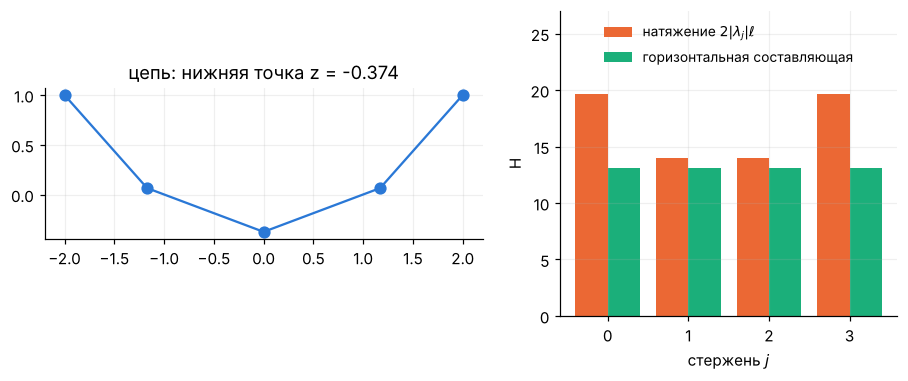

In [11]:
Fh, Fv = chk["Fh"], chk["Fv"]                                          # горизонтальная и вертикальная составляющие силы стержня j
print(f"горизонтальные 2 lambda_j dy_j: {Fh.round(3)} Н")
print(f"вертикальные   2 lambda_j dz_j: {Fv.round(3)} Н")
print(f"вертикальные на опорах: {abs(Fv[0]):.2f} + {abs(Fv[-1]):.2f} = {abs(Fv[0]) + abs(Fv[-1]):.2f} Н, вес цепи {ch['w'] * ch['N']:.2f} Н")
y, z = chain_xy(ch, v)                                                 # координаты с опорами
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
axes[0].plot(y, z, "o-", color=BLUE, ms=7); axes[0].set_aspect("equal"); axes[0].set_title(f"цепь: нижняя точка z = {z.min():.3f}")
j = np.arange(4)                                                       # номера стержней
axes[1].bar(j - 0.2, chk["F"], 0.4, color=ORANGE, label="натяжение $2|\\lambda_j|\\ell$")
axes[1].bar(j + 0.2, np.abs(Fh), 0.4, color=AQUA, label="горизонтальная составляющая")
axes[1].set_xticks(j); axes[1].set_xlabel("стержень $j$"); axes[1].set_ylabel("Н"); axes[1].set_ylim(0, 27)
axes[1].legend(fontsize=9, loc="upper center")
plt.show()

**Что видим.** Горизонтальная составляющая одна и та же во всех стержнях — это первое уравнение баланса из §5.1. Вертикальные: $14.72$, $4.91$, $-4.91$, $-14.72$. Соседние отличаются на вес груза $9.81$ — это второе уравнение. На опорах — по $14.72$ Н, вместе $29.43$ Н, ровно вес цепи.

## (e) Подробности

**Цена доходности. Что делает ячейка.** Решает портфель с двумя равенствами при цели $\rho=10\,\%$. Система условий здесь линейна, поэтому её решает `np.linalg.solve`. Затем сравнивает $\lambda_\rho$ с численной производной $f^\ast(\rho)$ и ищет цель, при которой доля первого актива становится нулём.

In [12]:
x, f_star, lam_pf = portfolio_eq(0.10)                                 # доли, риск и множители (бюджет, доходность)
d = 1e-5
fd = (portfolio_eq(0.10 + d)[1] - portfolio_eq(0.10 - d)[1]) / (2 * d)  # центральная разность df*/drho
print(f"x* = {np.round(x, 4)}, f* = {f_star:.6f}, lambda_rho = {lam_pf[1]:.4f}, df*/drho = {fd:.4f}")
rhos = np.linspace(0.06, 0.14, 801)
xa = np.array([portfolio_eq(r)[0][0] for r in rhos])                   # доля первого актива как функция цели
print(f"x_1 = 0 при rho = {rhos[np.argmin(np.abs(xa))] * 100:.2f} %")

x* = [0.0946 0.3822 0.3209 0.2023], f* = 0.008204, lambda_rho = 0.2571, df*/drho = 0.2571
x_1 = 0 при rho = 10.64 %


**Что видим.** $\lambda_\rho=0.2571$ и численная производная совпадают: множитель — цена доходности. При $\rho>10.64\,\%$ доля первого актива отрицательна. Тогда в задаче лекции 3 включается запрет $x\ge0$, и цена доходности другая: $0.47$ при $12\,\%$.

**Цена длины цепи. Что делает ячейка.** Удлиняет все стержни на $1\,\%$ и на $5\,\%$ и решает цепь заново. Сравнивает новый $f^\ast$ с предсказанием по множителям $f^\ast+\sum_j\lambda_j\,\Delta(\ell^2)$ — это первый порядок формулы цены.

In [13]:
ch = rod_chain(); v, lam, _ = solve_rod_chain(ch); f0 = ch["w"] * chain_xy(ch, v)[1][1:-1].sum()
for k in (1.01, 1.05):
    ch2 = rod_chain(L_total=5.0 * k)                                   # стержни длиннее на 1 % и 5 %
    v2, _, _ = solve_rod_chain(ch2, v0=v)                              # старт — старое решение
    f2 = ch2["w"] * chain_xy(ch2, v2)[1][1:-1].sum()
    pred = f0 + lam.sum() * (ch2["ell"] ** 2 - ch["ell"] ** 2)         # первый порядок: sum lambda_j d(ell^2)
    print(f"длина цепи × {k}: f* = {f2:.3f}, предсказание по множителям {pred:.3f}, расхождение {f2 - pred:.3f}")

длина цепи × 1.01: f* = -3.226, предсказание по множителям -3.239, расхождение 0.013
длина цепи × 1.05: f* = -6.408, предсказание по множителям -6.702, расхождение 0.294


**Что видим.** При $+1\,\%$ предсказание $-3.239$, пересчёт $-3.226$ — близко. При $+5\,\%$ — $-6.70$ против $-6.41$. Формула цены — производная, она верна в первом порядке; при большом сдвиге растёт вклад второго порядка.

**Лог IPOPT из двух стартов. Что делает ячейка.** Решает цепь из двух стартов: из опущенной прямой $z=0$ и из горизонтальной прямой $z=1$. Берёт из `solver.stats()["iterations"]` две невязки по итерациям: `inf_pr` $=\lVert g(x_k)\rVert_\infty$ и `inf_du` $=\lVert\nabla_xL(x_k,\lambda_k)\rVert_\infty$.

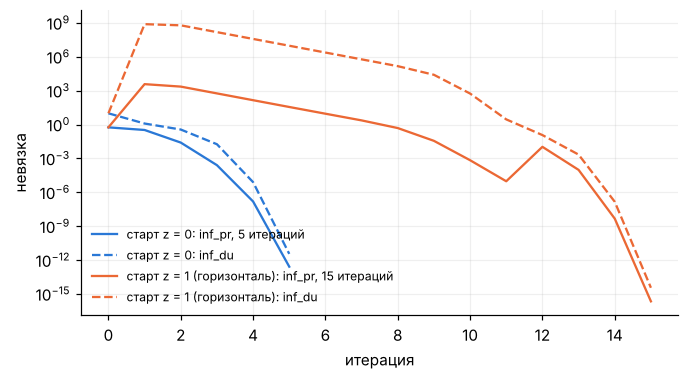

In [14]:
N = ch["N"]; t = np.linspace(-2, 2, N + 2)[1:-1]                      # y-координаты грузов на прямой
fig, ax = plt.subplots(figsize=(7, 3.6))
for name, z0, col in (("старт z = 0", np.zeros(N), BLUE), ("старт z = 1 (горизонталь)", np.ones(N), ORANGE)):
    v0 = np.concatenate([t, z0])                                       # стартовая точка: сначала все y, потом все z
    _, _, st = solve_rod_chain(ch, v0=v0)                              # IPOPT из этого старта
    it = st["iterations"]
    ax.semilogy(np.maximum(it["inf_pr"], 1e-17), "-", color=col, label=f"{name}: inf_pr, {st['iter_count']} итераций")
    ax.semilogy(np.maximum(it["inf_du"], 1e-17), "--", color=col, label=f"{name}: inf_du")
ax.set_xlabel("итерация"); ax.set_ylabel("невязка"); ax.legend(fontsize=8); plt.show()

**Что видим.** Из прямой $z=0$ — 5 итераций. Из горизонтали $z=1$ — 15, и `inf_du` по дороге доходит почти до $10^{9}$. На горизонтальной прямой все стержни лежат на одной линии. Вертикальный сдвиг не меняет их длин в первом порядке, и якобиан «не видит» это направление.

**Знак множителей у солверов. Что делают две ячейки.** IPOPT и SciPy `trust-constr` пишут функцию Лагранжа как $f+\lambda^\top g$, а конспект — как $f-\lambda^\top g$. Первая ячейка подставляет множители цепи в $\nabla f-J^\top\lambda$ с обоими знаками. Вторая решает задачу 1 через `trust-constr` и печатает его множитель `res.v`.

In [15]:
lam_g = -lam                                                           # так вернул IPOPT (solve_rod_chain меняет знак на наш)
J = ca.Function("J", [ch["v"]], [ca.jacobian(ch["g"], ch["v"])])(v).full()      # якобиан 4 x 6
gf = ca.Function("gf", [ch["v"]], [ca.gradient(ch["f"], ch["v"])])(v).full().ravel()   # grad f
print(f"|grad f - J^T lambda|  = {np.linalg.norm(gf - J.T @ lam):.1e}   (наш знак — ноль)")
print(f"|grad f - J^T lam_g|   = {np.linalg.norm(gf - J.T @ lam_g):.1e}   (знак IPOPT без поправки — не ноль)")
print(f"|grad f + J^T lam_g|   = {np.linalg.norm(gf + J.T @ lam_g):.1e}   (L = f + lam_g^T g — ноль)")

|grad f - J^T lambda|  = 4.5e-12   (наш знак — ноль)
|grad f - J^T lam_g|   = 3.4e+01   (знак IPOPT без поправки — не ноль)
|grad f + J^T lam_g|   = 4.5e-12   (L = f + lam_g^T g — ноль)


In [16]:
from scipy.optimize import minimize, NonlinearConstraint
a = A_CIRCLE
con = NonlinearConstraint(lambda x: 0.5 * (x @ x - 1), 0, 0, jac=lambda x: x.reshape(1, -1))   # g(x) = 1/2(|x|^2 - 1) = 0
res = minimize(lambda x: 0.5 * np.sum((x - a) ** 2), [1.0, 0.2], jac=lambda x: x - a, method="trust-constr",
               constraints=[con], options={"gtol": 1e-12, "xtol": 1e-14})
print(f"trust-constr: x = {res.x.round(4)}, res.v = {res.v[0][0]:+.4f}  ->  наш lambda = {-res.v[0][0]:+.4f} (в конспекте -1.236)")

trust-constr: x = [0.8944 0.4472], res.v = +1.2361  ->  наш lambda = -1.2361 (в конспекте -1.236)


**Что видим.** Невязка ноль получается с нашим знаком или со знаком солвера и плюсом. `trust-constr` вернул $+1.236$, а в конспекте $\lambda=-1.236$. Прежде чем читать множители солвера, проверьте его соглашение о знаке.

## Шпаргалка

| Что | Формула | Где в конспекте |
|---|---|---|
| касательное пространство | $T=\{p:\ Jp=0\}$, размерность $n-m$ | §2.2, §4.2 |
| первый порядок | $\nabla_xL=0$ и $g=0$ — $n+m$ уравнений | §2.3 |
| LICQ | $\operatorname{rank}J=m$ | §3.2 |
| второй порядок | $Z^\top\nabla^2_{xx}L\,Z\succ0$ | §4.2 |
| множитель — цена | $df^\ast/db=\lambda^\ast$ | §5.2 |
| знак у солверов | `lam_g` $=-\lambda$, `res.v` $=-\lambda$ | §6 |

**Три вещи, которые легко перепутать.**

1. Кривизну проверяют у $L$, а не у $f$. Слагаемое $-\lambda\nabla^2g$ — кривизна ограничений. У цепи на стержнях $\nabla^2f=0$, а минимум есть.
2. Знак $\lambda$ не говорит, минимум это или максимум. У окружности с $a=(0.3,0.1)$ в минимуме $\lambda>0$. Говорит редуцированный гессиан.
3. У IPOPT и SciPy множители с противоположным знаком: их функция Лагранжа $f+\lambda^\top g$.